# Install & imports

In [7]:
!pip install -q torch-geometric

import torch
import torch.nn as nn
import torch.nn.functional as torch_F
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score, roc_auc_score)
%matplotlib inline
import warnings, gc
warnings.filterwarnings('ignore')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

Device: cuda


# Reconnect paths, load train + val data

In [8]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_ROOT = Path('/content/drive/MyDrive/PD_EEG_Thesis_Features_v2')
FEAT_DIR     = PROJECT_ROOT / 'data' / 'features'
SPLIT_DIR    = PROJECT_ROOT / 'data' / 'split'
RESULTS_DIR  = PROJECT_ROOT / 'results'
FIG_DIR      = PROJECT_ROOT / 'figures'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

train_data = np.load(str(SPLIT_DIR / 'train_data.npz'))
nf_train, y_train = train_data['node_features'], train_data['y']

class_weights_dict = np.load(str(SPLIT_DIR / 'class_weights.npy'), allow_pickle=True).item()
class_weights_tensor = torch.tensor([class_weights_dict[0], class_weights_dict[1]], dtype=torch.float32).to(DEVICE)
print('Class weights loaded:', class_weights_dict)

# Val set — built fresh here (adjacency needs computing; features already exist)
d_full = np.load(str(FEAT_DIR / 'features_all.npz'))
node_features_full, y_full, subjects_full = d_full['node_features'], d_full['y'], d_full['subjects']

split_df = pd.read_csv(SPLIT_DIR / 'subject_split.csv')
val_subj = split_df.loc[split_df['split']=='val','subject'].astype(str).values
val_mask = np.isin(subjects_full, val_subj)
nf_val, y_val = node_features_full[val_mask], y_full[val_mask]

print(f'Train: {nf_train.shape}   Val: {nf_val.shape}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Class weights loaded: {0: 1.3935185185185186, 1: 0.7797927461139896}
Train: (2709, 6, 60, 17)   Val: (579, 6, 60, 17)


# Adjacency computation

In [ ]:
SEG_DIR = PROJECT_ROOT / 'data' / 'segments'
seg_d = np.load(str(SEG_DIR / 'segments_all.npz'))
X_raw, y_raw, subjects_raw = seg_d['X'], seg_d['y'], seg_d['subjects']

CORR_THRESHOLD = 0.3

def compute_adjacency(window):
    corr = np.nan_to_num(np.corrcoef(window), nan=0.0)
    adj  = np.where(corr >= CORR_THRESHOLD, corr, 0.0).astype(np.float32)
    np.fill_diagonal(adj, 0.0)
    return adj

train_subj_list = split_df.loc[split_df['split']=='train','subject'].astype(str).values
train_mask_raw = np.isin(subjects_raw, train_subj_list)
val_mask_raw   = np.isin(subjects_raw, val_subj)

adj_train = np.stack([compute_adjacency(X_raw[i]) for i in np.where(train_mask_raw)[0]])
adj_val   = np.stack([compute_adjacency(X_raw[i]) for i in np.where(val_mask_raw)[0]])

print(f'Adjacency — Train: {adj_train.shape}   Val: {adj_val.shape}')
assert adj_train.shape[0] == nf_train.shape[0], 'Train adjacency/feature count mismatch!'
assert adj_val.shape[0] == nf_val.shape[0], 'Val adjacency/feature count mismatch!'

Adjacency — Train: (2709, 60, 60)   Val: (579, 60, 60)


# Dataset class + model definitions

In [ ]:
class EEGFeatureGraphDataset(Dataset):
    def __init__(self, nf, adj, y):
        self.nf, self.adj, self.y = nf, adj, y
    def __len__(self): return len(self.y)
    def __getitem__(self, idx):
        return (torch.tensor(self.nf[idx], dtype=torch.float32),
                torch.tensor(self.adj[idx], dtype=torch.float32),
                torch.tensor(self.y[idx],  dtype=torch.long))

N_TIMESTEPS, N_FEATURES = 6, 17
HIDDEN_DIM, N_HEADS, DROPOUT = 48, 4, 0.25

class AttentionPool(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.attn = nn.Linear(hidden_dim, 1)
    def forward(self, emb):
        weights = torch_F.softmax(self.attn(emb), dim=1)
        return (weights * emb).sum(dim=1), weights.squeeze(-1)

class TGCN(nn.Module):
    def __init__(self, n_features, hidden_dim, dropout):
        super().__init__()
        self.gc_weight  = nn.Linear(n_features, hidden_dim, bias=False)
        self.pool       = AttentionPool(hidden_dim)
        self.gru        = nn.GRU(hidden_dim, hidden_dim, batch_first=True, num_layers=2, dropout=dropout)
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, 2)
    def graph_conv(self, x, adj):
        deg = adj.sum(dim=-1, keepdim=True).clamp(min=1)
        x   = torch.bmm(adj / deg, x)
        return torch_F.relu(self.gc_weight(x))
    def forward(self, node_feat, adj):
        B, T, N, Fdim = node_feat.shape
        embs = [self.pool(self.graph_conv(node_feat[:, t], adj))[0] for t in range(T)]
        seq, _ = self.gru(torch.stack(embs, dim=1))
        return self.classifier(self.dropout(seq[:, -1, :]))

class TGIN(nn.Module):
    def __init__(self, n_features, hidden_dim, dropout):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(n_features, hidden_dim), nn.ReLU(), nn.Linear(hidden_dim, hidden_dim))
        self.eps  = nn.Parameter(torch.zeros(1))
        self.pool = AttentionPool(hidden_dim)
        self.gru  = nn.GRU(hidden_dim, hidden_dim, batch_first=True, num_layers=2, dropout=dropout)
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, 2)
    def graph_gin(self, x, adj):
        agg = torch.bmm(adj, x)
        return self.mlp((1 + self.eps) * x + agg)
    def forward(self, node_feat, adj):
        B, T, N, Fdim = node_feat.shape
        embs = [self.pool(self.graph_gin(node_feat[:, t], adj))[0] for t in range(T)]
        seq, _ = self.gru(torch.stack(embs, dim=1))
        return self.classifier(self.dropout(seq[:, -1, :]))

class TGAT(nn.Module):
    def __init__(self, n_features, hidden_dim, n_heads, dropout):
        super().__init__()
        self.n_heads, self.head_dim = n_heads, hidden_dim // n_heads
        self.W_q = nn.Linear(n_features, hidden_dim, bias=False)
        self.W_k = nn.Linear(n_features, hidden_dim, bias=False)
        self.W_v = nn.Linear(n_features, hidden_dim, bias=False)
        self.W_o = nn.Linear(hidden_dim, hidden_dim)
        self.gru        = nn.GRU(hidden_dim, hidden_dim, batch_first=True, num_layers=2, dropout=dropout)
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, 2)
    def graph_attention(self, x, adj):
        B, N, Fdim = x.shape
        H, D = self.n_heads, self.head_dim
        Q = self.W_q(x).view(B, N, H, D).transpose(1, 2)
        K = self.W_k(x).view(B, N, H, D).transpose(1, 2)
        V = self.W_v(x).view(B, N, H, D).transpose(1, 2)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (D ** 0.5)
        mask   = (adj == 0).unsqueeze(1).expand_as(scores)
        scores = scores.masked_fill(mask, float('-inf'))
        scores = torch.nan_to_num(scores, nan=0.0, neginf=-1e9)
        attn   = torch_F.softmax(scores, dim=-1)
        out    = torch.matmul(attn, V).transpose(1, 2).contiguous().view(B, N, -1)
        return torch_F.relu(self.W_o(out))
    def forward(self, node_feat, adj):
        B, T, N, Fdim = node_feat.shape
        embs = [self.graph_attention(node_feat[:, t], adj).mean(dim=1) for t in range(T)]
        seq, _ = self.gru(torch.stack(embs, dim=1))
        return self.classifier(self.dropout(seq[:, -1, :]))

def build_model(name):
    if name == 'TGCN': return TGCN(N_FEATURES, HIDDEN_DIM, DROPOUT).to(DEVICE)
    if name == 'TGIN': return TGIN(N_FEATURES, HIDDEN_DIM, DROPOUT).to(DEVICE)
    if name == 'TGAT': return TGAT(N_FEATURES, HIDDEN_DIM, N_HEADS, DROPOUT).to(DEVICE)

print('Models ready.')

Models ready.


# Train/eval utilities

In [ ]:
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    total = 0
    for nf, adj, y in loader:
        nf, adj, y = nf.to(DEVICE), adj.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(nf, adj), y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total += loss.item()
    return total / len(loader)

def evaluate(model, loader):
    model.eval()
    preds, probs, labels = [], [], []
    with torch.no_grad():
        for nf, adj, y in loader:
            nf, adj = nf.to(DEVICE), adj.to(DEVICE)
            logits = model(nf, adj)
            probs.extend(torch_F.softmax(logits, dim=1)[:, 1].cpu().numpy())
            preds.extend(logits.argmax(dim=1).cpu().numpy())
            labels.extend(y.numpy())
    preds, probs, labels = map(np.array, (preds, probs, labels))
    return {
        'accuracy': accuracy_score(labels, preds),
        'balanced_accuracy': balanced_accuracy_score(labels, preds),
        'f1': f1_score(labels, preds, zero_division=0),
        'auc': roc_auc_score(labels, probs)
    }, probs, labels

# Train all three models — loss/accuracy tracking, best-BalAcc checkpointing

In [ ]:
MODEL_NAMES = ['TGCN', 'TGIN', 'TGAT']
BATCH_SIZE, MAX_EPOCHS, LR, WEIGHT_DECAY = 32, 100, 1e-3, 1e-4
PATIENCE_PER_MODEL = {'TGCN': 15, 'TGIN': 25, 'TGAT': 15}   # TGIN gets more patience —
                                                              # it collapsed to majority-class
                                                              # prediction after only 18 epochs
RANDOM_STATE = 42

train_loader = DataLoader(EEGFeatureGraphDataset(nf_train, adj_train, y_train),
                          batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(EEGFeatureGraphDataset(nf_val, adj_val, y_val), batch_size=BATCH_SIZE, num_workers=2)

training_histories = {}

for model_name in MODEL_NAMES:
    print(f'\n{"="*50}\n{model_name}\n{"="*50}')
    torch.manual_seed(RANDOM_STATE)
    model     = build_model(model_name)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)
    criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
    patience  = PATIENCE_PER_MODEL[model_name]

    history = {'train_loss': [], 'val_loss': [], 'val_balacc': [], 'val_auc': []}

    # CHANGED: track BEST BALANCED ACCURACY for checkpoint selection, not val_loss/F1 —
    # F1 can look fine during majority-class collapse; balanced accuracy cannot.
    best_val_balacc, wait, best_state = 0.0, 0, None

    for epoch in range(MAX_EPOCHS):
        train_loss = train_epoch(model, train_loader, optimizer, criterion)
        val_metrics, val_probs, _ = evaluate(model, val_loader)
        val_loss = 1 - val_metrics['f1']
        scheduler.step(val_loss)   # scheduler can still watch F1-based loss, that's fine

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_balacc'].append(val_metrics['balanced_accuracy'])
        history['val_auc'].append(val_metrics['auc'])

        # Collapse detector — flag if predictions are becoming degenerate DURING training
        pred_variety = len(np.unique((val_probs >= 0.5).astype(int)))
        if (epoch + 1) % 10 == 0:
            print(f'  Epoch {epoch+1}: val_BalAcc={val_metrics["balanced_accuracy"]:.3f}  '
                  f'val_AUC={val_metrics["auc"]:.3f}  '
                  f'{"⚠️ COLLAPSED (single-class predictions)" if pred_variety < 2 else ""}')

        # CHANGED: checkpoint on best BalAcc, not best val_loss —
        # this ensures we keep the model's genuine peak, even if it later
        # collapses into a state where F1 looks fine but BalAcc craters.
        if val_metrics['balanced_accuracy'] > best_val_balacc:
            best_val_balacc, wait = val_metrics['balanced_accuracy'], 0
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})

    # Final collapse check before saving — refuse to save a degenerate checkpoint silently
    final_val_metrics, final_val_probs, _ = evaluate(model, val_loader)
    final_pred_variety = len(np.unique((final_val_probs >= 0.5).astype(int)))
    if final_pred_variety < 2:
        print(f'  🛑 WARNING: {model_name} final checkpoint is collapsed. This should not happen now.')
    else:
        print(f'  ✓ Checkpoint verified non-degenerate. Final val BalAcc: {final_val_metrics["balanced_accuracy"]:.3f}')

    torch.save(best_state, str(RESULTS_DIR / f'{model_name}_trained.pt'))
    training_histories[model_name] = history
    print(f'Stopped @ epoch {epoch+1}  |  Best val BalAcc (checkpoint saved): {best_val_balacc:.3f}')

    del model
    gc.collect(); torch.cuda.empty_cache()

print('\n\nAll models trained.')


TGCN
  Epoch 10: val_BalAcc=0.587  val_AUC=0.627  
  Epoch 20: val_BalAcc=0.693  val_AUC=0.774  
  Epoch 30: val_BalAcc=0.713  val_AUC=0.781  
  Epoch 40: val_BalAcc=0.702  val_AUC=0.743  
  ✓ Checkpoint verified non-degenerate. Final val BalAcc: 0.716
Stopped @ epoch 48  |  Best val BalAcc (checkpoint saved): 0.716

TGIN
  Epoch 10: val_BalAcc=0.657  val_AUC=0.661  
  Epoch 20: val_BalAcc=0.665  val_AUC=0.698  
  Epoch 30: val_BalAcc=0.671  val_AUC=0.714  
  ✓ Checkpoint verified non-degenerate. Final val BalAcc: 0.711
Stopped @ epoch 33  |  Best val BalAcc (checkpoint saved): 0.711

TGAT
  Epoch 10: val_BalAcc=0.640  val_AUC=0.751  
  Epoch 20: val_BalAcc=0.696  val_AUC=0.764  
  Epoch 30: val_BalAcc=0.698  val_AUC=0.771  
  Epoch 40: val_BalAcc=0.742  val_AUC=0.803  
  Epoch 50: val_BalAcc=0.755  val_AUC=0.803  
  ✓ Checkpoint verified non-degenerate. Final val BalAcc: 0.762
Stopped @ epoch 56  |  Best val BalAcc (checkpoint saved): 0.762


All models trained.


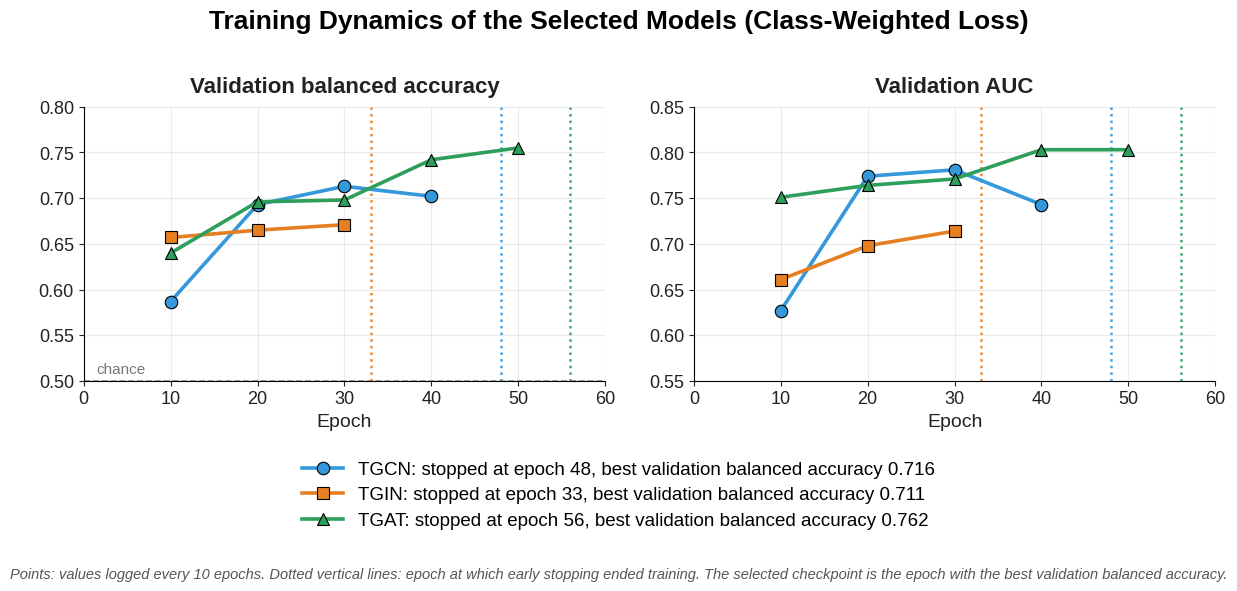

Saved -> /content/drive/MyDrive/PD_EEG_Thesis_Features_v2/figures/Slide17_Training_Dynamics.png


In [9]:
# Slide 17 figure: training dynamics of the selected (original) run.
# Standalone: uses the values printed by the original Notebook 7 log (every 10 epochs).
# It does NOT train anything and does NOT touch results/ or any checkpoint.
import matplotlib.pyplot as plt
from pathlib import Path

try:
    FIG_DIR = Path(PROJECT_ROOT) / 'figures'          # uses PROJECT_ROOT if it is already defined
except NameError:
    FIG_DIR = Path('/content/drive/MyDrive/PD_EEG_Thesis_Features_v2') / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Liberation Sans', 'Arial', 'DejaVu Sans']

# ---- values logged every 10 epochs by the ORIGINAL training run (Notebook 7 output) ----
LOG = {
    'TGCN': dict(ep=[10, 20, 30, 40],     bal=[0.587, 0.693, 0.713, 0.702],        auc=[0.627, 0.774, 0.781, 0.743],        stop=48, best=0.716),
    'TGIN': dict(ep=[10, 20, 30],         bal=[0.657, 0.665, 0.671],               auc=[0.661, 0.698, 0.714],               stop=33, best=0.711),
    'TGAT': dict(ep=[10, 20, 30, 40, 50], bal=[0.640, 0.696, 0.698, 0.742, 0.755], auc=[0.751, 0.764, 0.771, 0.803, 0.803], stop=56, best=0.762),
}
COL = {'TGCN': '#3498DB', 'TGIN': '#E67E22', 'TGAT': '#2E9E5B'}
MARK = {'TGCN': 'o', 'TGIN': 's', 'TGAT': '^'}
INK = '#222222'

fig, axes = plt.subplots(1, 2, figsize=(12.3, 5.9))
fig.subplots_adjust(left=0.065, right=0.985, top=0.82, bottom=0.355, wspace=0.17)

for ax, key, title, ylo, yhi in ((axes[0], 'bal', 'Validation balanced accuracy', 0.50, 0.80),
                                  (axes[1], 'auc', 'Validation AUC', 0.55, 0.85)):
    for m, d in LOG.items():
        ax.plot(d['ep'], d[key], color=COL[m], lw=2.6, marker=MARK[m], ms=9, mec='black', mew=0.8, zorder=3)
        ax.axvline(d['stop'], color=COL[m], ls=':', lw=1.8, alpha=0.9, zorder=1)
    if key == 'bal':
        ax.axhline(0.5, color='#888888', ls='--', lw=1.2, zorder=1)
        ax.text(1.5, 0.505, 'chance', fontsize=11, color='#777777', va='bottom')
    ax.set_xlim(0, 60); ax.set_ylim(ylo, yhi)
    ax.set_xlabel('Epoch', fontsize=14, color=INK)
    ax.set_title(title, fontsize=16, fontweight='bold', color=INK, pad=10)
    ax.tick_params(labelsize=13, colors=INK)
    ax.grid(alpha=0.25)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)

handles = [plt.Line2D([0], [0], color=COL[m], lw=2.6, marker=MARK[m], ms=9, mec='black', mew=0.8,
                      label=f"{m}: stopped at epoch {d['stop']}, best validation balanced accuracy {d['best']:.3f}")
           for m, d in LOG.items()]
fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.075), ncol=1, frameon=False, fontsize=13.5,
           handlelength=2.2, labelspacing=0.45)
fig.suptitle('Training Dynamics of the Selected Models (Class-Weighted Loss)', fontsize=19, fontweight='bold', y=0.985)
fig.text(0.5, 0.028, 'Points: values logged every 10 epochs. Dotted vertical lines: epoch at which early stopping ended training. '
         'The selected checkpoint is the epoch with the best validation balanced accuracy.',
         ha='center', va='center', fontsize=10.5, color='#555555', style='italic')

out_path = FIG_DIR / 'Slide17_Training_Dynamics.png'
fig.savefig(str(out_path), dpi=300, facecolor='white')
plt.show()
print(f'Saved -> {out_path}')